# 7장 3차시 : 모델을 고르고, 믿을 수 있는지 재는 법
수업에서 보여 주는 셀입니다. 4차시에 `sales_clean.csv` 로 직접 칩니다.

In [1]:
import sklearn
print(sklearn.__version__)

1.9.1


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

iris = load_iris(as_frame=True)
X = iris.frame[iris.feature_names]
y = iris.target_names[iris.target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

## 1. 모델은 하나가 아니다

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "decision tree (depth 2)": DecisionTreeClassifier(max_depth=2, random_state=0),
    "logistic regression":      LogisticRegression(max_iter=1000),
    "kNN (k=5)":       KNeighborsClassifier(n_neighbors=5),
    "random forest":      RandomForestClassifier(n_estimators=100, random_state=0),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name:24s} training {m.score(X_train, y_train):.3f}  test {m.score(X_test, y_test):.3f}")

decision tree (depth 2)  training 0.958  test 0.967
logistic regression      training 0.967  test 1.000
kNN (k=5)                training 0.950  test 0.967


random forest            training 1.000  test 1.000


In [4]:
new = pd.DataFrame([[6.1, 2.6, 5.6, 1.4]], columns=iris.feature_names)
for name, m in models.items():
    print(f"{name:24s} {m.predict(new)[0]:12s} {m.predict_proba(new).round(2)}")

decision tree (depth 2)  versicolor   [[0.  0.9 0.1]]
logistic regression      virginica    [[0.   0.19 0.81]]
kNN (k=5)                virginica    [[0.  0.2 0.8]]
random forest            virginica    [[0.   0.48 0.52]]


In [5]:
import joblib

rf = models["random forest"]
joblib.dump(rf, "iris_model.pkl")
try:
    from google.colab import files
    files.download("iris_model.pkl")
except ImportError:
    pass

## 2. 과적합 : 깊이를 늘리면 (반품 데이터)

In [6]:
sales = pd.read_csv("sales_clean.csv")
d = sales.dropna(subset=["customer_age", "satisfaction"])
Xr = d[["quantity", "unit_price", "customer_age", "satisfaction"]]
yr = (d["status"] == "반품").astype(int)          # 반품 1, 아니면 0
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=0)
print("training :", len(Xr_train), " test :", len(Xr_test))
print("return rate :", round(yr.mean() * 100, 1), "%   baseline (모두 아니오) test accuracy :", round((yr_test == 0).mean(), 3))

training : 738  test : 185
return rate : 8.0 %   baseline (모두 아니오) test accuracy : 0.892


In [7]:
rows = []
for dep in [1, 2, 3, 5, 8, None]:
    m = DecisionTreeClassifier(max_depth=dep, random_state=0).fit(Xr_train, yr_train)
    rows.append([str(dep), m.get_n_leaves(),
                 round(m.score(Xr_train, yr_train), 3), round(m.score(Xr_test, yr_test), 3)])
tbl = pd.DataFrame(rows, columns=["max_depth", "leaves", "training", "test"])
tbl

,max_depth,leaves,training,test
0,1,2,0.927,0.892
1,2,4,0.928,0.892
2,3,7,0.931,0.870
3,5,16,0.938,0.865
4,8,37,0.953,0.854
5,None,98,1.000,0.811


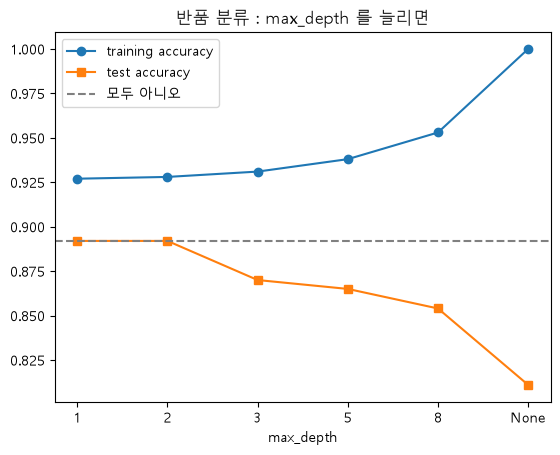

In [8]:
plt.plot(range(6), tbl["training"], "o-", label="training accuracy")
plt.plot(range(6), tbl["test"], "s-", label="test accuracy")
plt.axhline((yr_test == 0).mean(), color="gray", ls="--", label="모두 아니오")
plt.xticks(range(6), tbl["max_depth"]); plt.xlabel("max_depth")
plt.title("반품 분류 : max_depth 를 늘리면"); plt.legend(); plt.show()

## 3. 교차검증 : 나눔 한 번을 믿지 않는다

In [9]:
from sklearn.model_selection import cross_val_score

m = DecisionTreeClassifier(max_depth=2, random_state=0)
scores = cross_val_score(m, X, y, cv=5)       # 150 송이를 5 조각으로
print(scores.round(3))
print("mean :", scores.mean().round(3), " std :", scores.std().round(3))

[0.933 0.967 0.9   0.867 1.   ]
mean : 0.933  std : 0.047


## 4. 특징 만들기 : 선형 회귀는 곱셈을 모른다

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

Xs = sales[["quantity", "unit_price"]]
ys = sales["total_sales"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.2, random_state=0)

lin = LinearRegression().fit(Xs_train, ys_train)
print("linear (quantity, unit_price)     test R² :", round(lin.score(Xs_test, ys_test), 3))

print("coef :", lin.coef_.round(1), " intercept :", round(lin.intercept_, 1))

Xs2_train = Xs_train.assign(qp=Xs_train["quantity"] * Xs_train["unit_price"])
Xs2_test  = Xs_test.assign(qp=Xs_test["quantity"] * Xs_test["unit_price"])
lin2 = LinearRegression().fit(Xs2_train, ys_train)
print("linear (quantity, unit_price, qp) test R² :", round(lin2.score(Xs2_test, ys_test), 3))
print("coef :", lin2.coef_.round(3), " intercept :", round(lin2.intercept_, 1))

linear (quantity, unit_price)     test R² : 0.862
coef : [2.515409e+05 4.900000e+01]  intercept : -12387684.5
linear (quantity, unit_price, qp) test R² : 1.0
coef : [0. 0. 1.]  intercept : -0.0


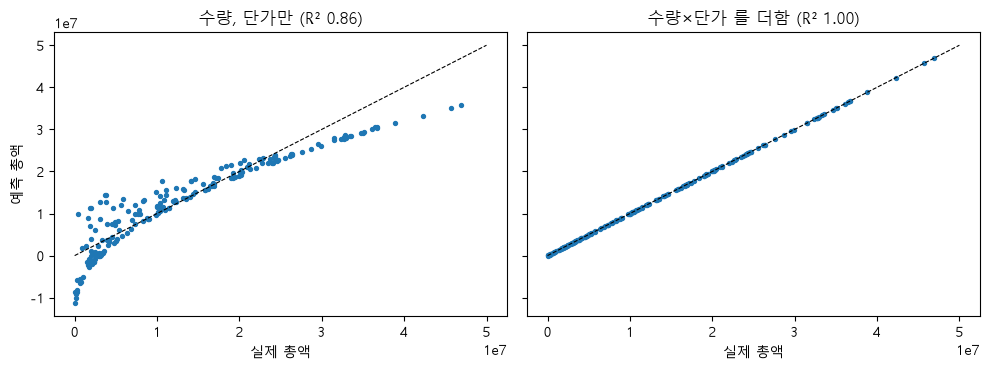

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
ax[0].scatter(ys_test, lin.predict(Xs_test), s=8);  ax[0].set_title("수량, 단가만 (R² 0.86)")
ax[1].scatter(ys_test, lin2.predict(Xs2_test), s=8); ax[1].set_title("수량×단가 를 더함 (R² 1.00)")
for a in ax:
    a.plot([0, 5e7], [0, 5e7], "k--", lw=0.8); a.set_xlabel("실제 총액")
ax[0].set_ylabel("예측 총액")
plt.tight_layout(); plt.show()

In [12]:
pd.get_dummies(sales[["quantity", "category"]], dtype=int).head(3)

,quantity,category_가구,category_도서,category_식품,category_의류,category_전자제품
0,61,0,0,0,0,1
1,64,0,0,1,0,0
2,5,0,0,0,1,0


## 5. 쏠린 분류의 평가 : 정밀도와 재현율

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

clf = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xr_train, yr_train)
pred = clf.predict(Xr_test)
print("accuracy  :", round(clf.score(Xr_test, yr_test), 3),
      "  baseline (모두 아니오) :", round((yr_test == 0).mean(), 3))
print("precision :", round(precision_score(yr_test, pred, zero_division=0), 3),
      "  recall :", round(recall_score(yr_test, pred), 3))
pd.DataFrame(confusion_matrix(yr_test, pred),
             index=["true_no", "true_return"],
             columns=["pred_no", "pred_return"])

accuracy  : 0.87   baseline (모두 아니오) : 0.892
precision : 0.0   recall : 0.0


,pred_no,pred_return
true_no,161,4
true_return,20,0


## 6. PCA : 4차원을 2차원 그림으로

explained variance ratio : [0.73  0.229]  sum : 0.958


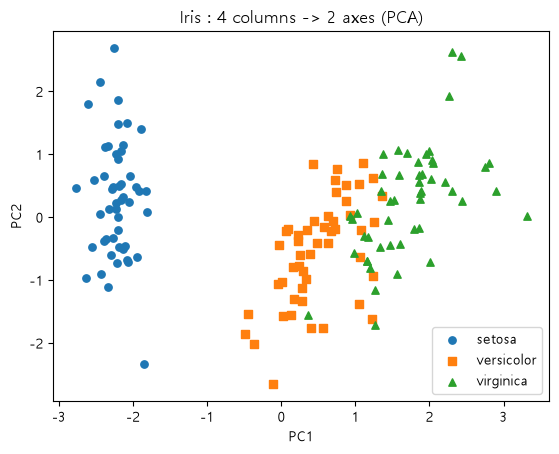

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Xz = StandardScaler().fit_transform(X)          # 열마다 평균 0, 표준편차 1
pca = PCA(n_components=2)
P = pca.fit_transform(Xz)
print("explained variance ratio :", pca.explained_variance_ratio_.round(3),
      " sum :", pca.explained_variance_ratio_.sum().round(3))
markers = {"setosa": "o", "versicolor": "s", "virginica": "^"}
for name in iris.target_names:
    sel = (y == name)
    plt.scatter(P[sel, 0], P[sel, 1], marker=markers[name], label=name, s=28)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Iris : 4 columns -> 2 axes (PCA)")
plt.legend(); plt.show()

In [15]:
pd.Series(pca.components_[0], index=iris.feature_names).round(2)

sepal length (cm)    0.52
sepal width (cm)    -0.27
petal length (cm)    0.58
petal width (cm)     0.56
dtype: float64

explained variance ratio : [0.362 0.192]  sum : 0.554


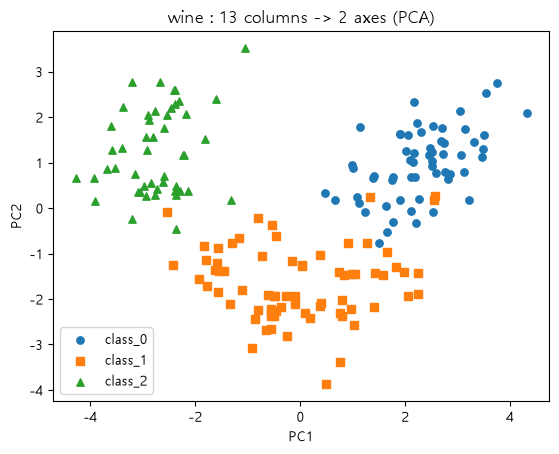

In [16]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
Xw = wine.frame[wine.feature_names]
yw = wine.target_names[wine.target]
Pw = PCA(n_components=2).fit(StandardScaler().fit_transform(Xw))
Pw2 = Pw.transform(StandardScaler().fit_transform(Xw))
print("explained variance ratio :", Pw.explained_variance_ratio_.round(3),
      " sum :", Pw.explained_variance_ratio_.sum().round(3))
for name, mk in zip(wine.target_names, ["o", "s", "^"]):
    sel = (yw == name)
    plt.scatter(Pw2[sel, 0], Pw2[sel, 1], marker=mk, label=name, s=28)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("wine : 13 columns -> 2 axes (PCA)")
plt.legend(); plt.show()

## 7. time series : 다음 달 CO2 농도를 예측한다

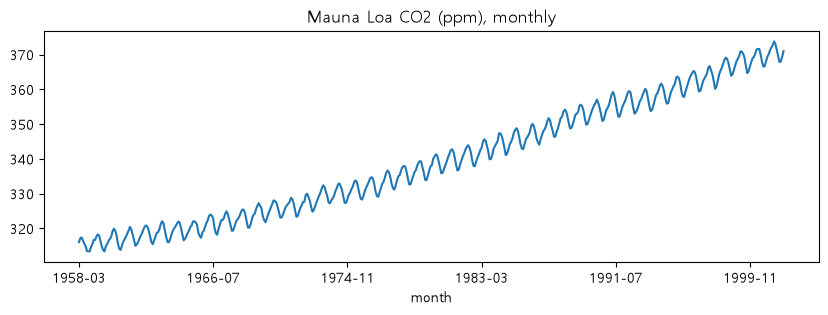

,month,co2
523,2001-10,368.05
524,2001-11,369.38
525,2001-12,371.02


In [17]:
co2 = pd.read_csv("co2_monthly.csv")        # 1958-03 ~ 2001-12, 월 평균 (ppm)
y = co2["co2"]
co2.plot(x="month", y="co2", figsize=(10, 3), legend=False, title="Mauna Loa CO2 (ppm), monthly")
plt.show()
co2.tail(3)

In [18]:
print(co2.shape)
lags = pd.DataFrame({"co2": y, "lag1": y.shift(1), "lag2": y.shift(2), "lag12": y.shift(12)})
lags.head(14)

(526, 2)


,co2,lag1,lag2,lag12
0,316.10,NaN,NaN,NaN
1,317.20,316.10,NaN,NaN
2,317.43,317.20,316.10,NaN
3,316.53,317.43,317.20,NaN
4,315.62,316.53,317.43,NaN
5,314.95,315.62,316.53,NaN
6,313.50,314.95,315.62,NaN
7,313.46,313.50,314.95,NaN
8,313.42,313.46,313.50,NaN
9,314.70,313.42,313.46,NaN


In [19]:
# feature : 지난 12 달의 값 (lag). label : 이번 달의 값
X = pd.DataFrame({f"lag{k}": y.shift(k) for k in range(1, 13)}).dropna()
y_ts = y.loc[X.index]
print(X.shape, y_ts.shape)
X.tail(2)

(514, 12) (514,)


,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,lag10,lag11,lag12
524,368.05,367.88,369.42,371.30,373.06,373.80,372.78,372.06,371.32,370.18,369.44,368.12
525,369.38,368.05,367.88,369.42,371.30,373.06,373.80,372.78,372.06,371.32,370.18,369.44


In [20]:
# 시간 순서대로 나눈다. 섞지 않는다 : 마지막 60 달 (5 년) 이 test
n = 60
X_train, X_test = X[:-n], X[-n:]
y_train, y_test = y_ts[:-n], y_ts[-n:]
print("training :", len(X_train), " test :", len(X_test))

training : 454  test : 60


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)
print("linear regression (12 lags)  MAE :", round(mean_absolute_error(y_test, pred), 3), "ppm")
print("baseline : 지난달 값 그대로     MAE :", round(mean_absolute_error(y_test, X_test["lag1"]), 3))
print("baseline : 작년 같은 달 그대로  MAE :", round(mean_absolute_error(y_test, X_test["lag12"]), 3))

linear regression (12 lags)  MAE : 0.369 ppm
baseline : 지난달 값 그대로     MAE : 1.113
baseline : 작년 같은 달 그대로  MAE : 1.653


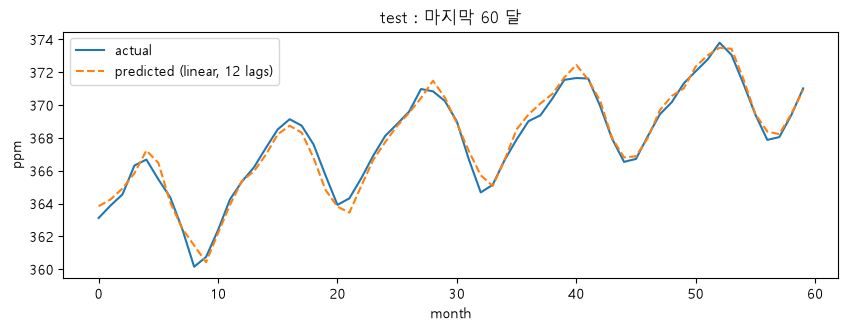

In [22]:
plt.figure(figsize=(10, 3.2))
plt.plot(y_test.values, label="actual")
plt.plot(pred, "--", label="predicted (linear, 12 lags)")
plt.title("test : 마지막 60 달"); plt.xlabel("month"); plt.ylabel("ppm"); plt.legend()
plt.show()

In [23]:
tree = DecisionTreeRegressor(random_state=0).fit(X_train, y_train)
print("decision tree  MAE :", round(mean_absolute_error(y_test, tree.predict(X_test)), 3),
      "  R² :", round(tree.score(X_test, y_test), 3))
print("max of training :", round(y_train.max(), 2), "  max of test :", round(y_test.max(), 2))

decision tree  MAE : 3.501   R² : -0.922
max of training : 365.32   max of test : 373.8


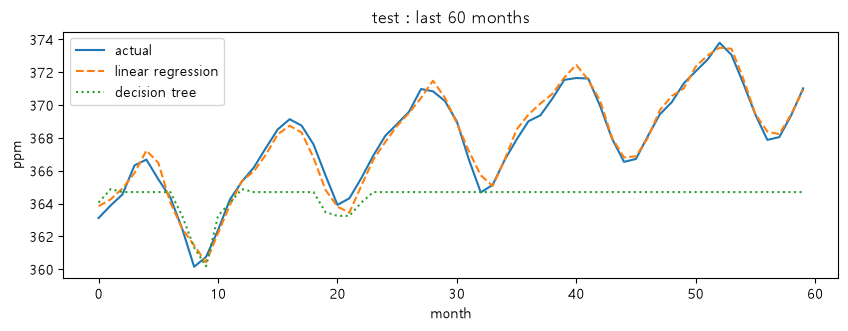

In [24]:
plt.figure(figsize=(10, 3.2))
plt.plot(y_test.values, label="actual")
plt.plot(pred, "--", label="linear regression")
plt.plot(tree.predict(X_test), ":", label="decision tree")
plt.title("test : last 60 months"); plt.xlabel("month"); plt.ylabel("ppm"); plt.legend()
plt.show()